# Random Number Generators

In these exercises, you will analyze statistical properties of data generated by different Random Number Generators (RNGs).

## Preparation

For shell command calls, the Python module ``subprocess`` is used (https://docs.python.org/3/library/subprocess.html).

Run the following code block to provide the functions ``execute_vm_command()`` and ``execute_stm32_command()`` within this notebook.

In [3]:
import subprocess

def execute_vm_command(cmd):
    run = subprocess.run(cmd, universal_newlines=True, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(run.stdout)
    
def execute_stm32_command(cmd):
    ssh = 'sshpass -p "root" ssh root@192.168.13.13 '
    run = subprocess.run((ssh + cmd), universal_newlines=True, shell=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(run.stdout)

Of course, all shell commands given in this tutorial can also be executed directly on a Linux console.

If you want to open a terminal window, execute the next code block.

In [4]:
execute_vm_command('gnome-terminal')

---

## Statistical Analysis of Random Numbers

There are many statistical methods to assess the quality of random numbers, e.g. explained in NIST's SP800 90B, and this topic is all but trivial. However, knowing some basic analysis methods is sometimes enough to distinguish between reasonable and not usable RNGs.

The following sections introduce a selection of common tests to get a first impression of statistical randomness properties:

* Distributions of m-bit Tuples
* Autocorrelation analysis
* Compression Test

### Distributions of m-bit Tuples

A fundamental property of random numbers is that each possible number should occur with the same probability. By analyzing the distributions of numbers in a data set, biases and skewness can be detected.

This starts when looking at the distribution of 0s and 1s, and can be continued with 2-bit (00, 01, 10, 11), 3-bit and further m-bit tuples.

The following code performs a 1-bit, 2-bit and 4-bit tuple analysis on the test data in ``rng_data/test_data0.bin`` and ``rng_data/test_data1.bin``.

In [5]:
def generate_tuples(data_file):
    data_1bit = []
    data_2bit = []
    data_4bit = []

    # open file for binary reading
    with open(data_file, 'rb') as f:
        byte = f.read(1)
        while byte != b'':
            byte = byte[0]

            # convert byte into 8x 1 bit
            data_1bit.append(byte      & 1)
            data_1bit.append(byte >> 1 & 1)
            data_1bit.append(byte >> 2 & 1)
            data_1bit.append(byte >> 3 & 1)
            data_1bit.append(byte >> 4 & 1)
            data_1bit.append(byte >> 5 & 1)
            data_1bit.append(byte >> 6 & 1)
            data_1bit.append(byte >> 7 & 1)
        
            # convert byte into 4x 2-bit tuple
            data_2bit.append(byte      & 3)
            data_2bit.append(byte >> 2 & 3)
            data_2bit.append(byte >> 4 & 3)
            data_2bit.append(byte >> 6 & 3)
        
            # convert byte into 2x 4-bit tuple
            data_4bit.append(byte      & 15)
            data_4bit.append(byte >> 4 & 15)

            # read next byte
            byte = f.read(1)

    return [data_1bit, data_2bit, data_4bit]

data_file0 = 'rng_data/test_data0.bin'
data_file1 = 'rng_data/test_data1.bin'

tuple_data0 = generate_tuples(data_file0)
tuple_data1 = generate_tuples(data_file1)

Visualizations of distributions can help to expose possible irregularities.

Therefore, the following code block uses the Python library ``matplotlib`` to plot histograms of the generated tuple data sets.

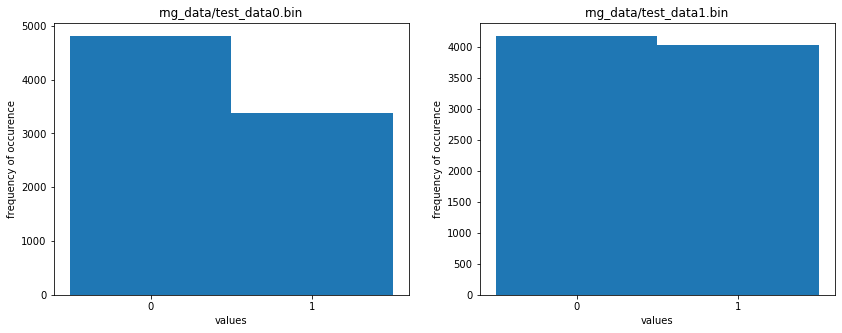

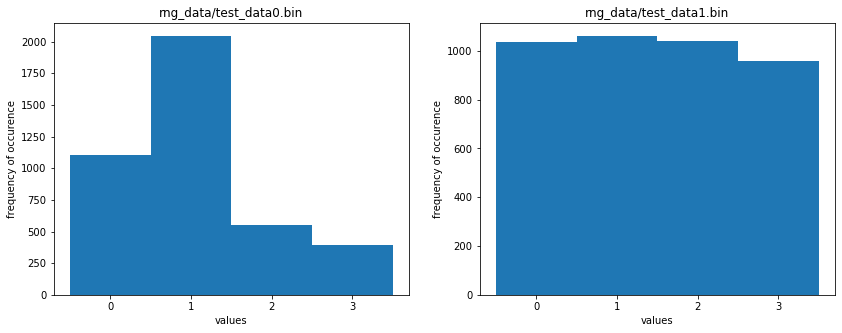

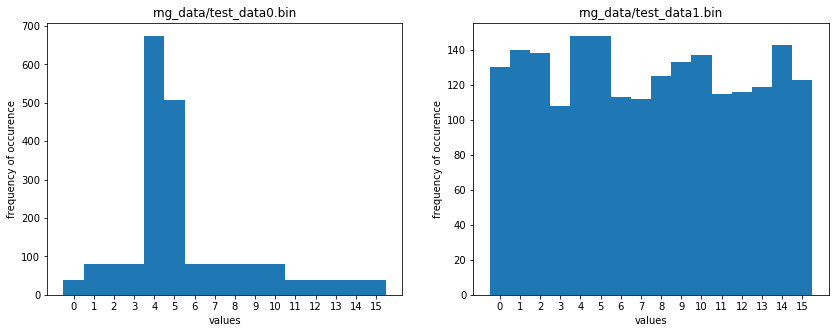

In [6]:
%matplotlib inline

import matplotlib.pyplot as plt

def plot_hist(ax, title, bits, data):
    ax.hist(data, bins=range(2**bits+1), align='left')
    ax.set_title(title)
    ax.set_xlabel('values')
    ax.set_xticks(range(2**bits))
    ax.set_ylabel('frequency of occurence')

fig1 = plt.figure(figsize=(14, 5)) 
ax1 = plt.subplot(1, 2, 1)
plot_hist(ax1, data_file0, 1, tuple_data0[0])
ax2 = plt.subplot(1, 2, 2)
plot_hist(ax2, data_file1, 1, tuple_data1[0])
plt.show()

fig2 = plt.figure(figsize=(14, 5)) 
ax1 = plt.subplot(1, 2, 1)
plot_hist(ax1, data_file0, 2, tuple_data0[1])
ax2 = plt.subplot(1, 2, 2)
plot_hist(ax2, data_file1, 2, tuple_data1[1])
plt.show()

fig3 = plt.figure(figsize=(14, 5)) 
ax1 = plt.subplot(1, 2, 1)
plot_hist(ax1, data_file0, 4, tuple_data0[2])
ax2 = plt.subplot(1, 2, 2)
plot_hist(ax2, data_file1, 4, tuple_data1[2])
plt.show()

### Autocorrelation Analysis

The correlation between two data sets is a measure for their similarity. For autocorrelation, one data set is correlated with a shifted version of itself. This analysis can exhibit dependencies between subsequent random numbers, which is -- of course -- not desired for good randomness.

The following code performs autocorrelation on the test data files ``rng_data/test_data0.bin`` and ``rng_data/test_data1.bin``.

**Hint:**<br>
Autocorrelation is a resource-intensive calculation. Use the variable ``n_bytes_to_read`` to limit the number of bytes that are read from the test data and used for autocorrelation.

In [7]:
import numpy as np

def autocorrelate(data_file):

    # limit number of bytes to read
    n_bytes_to_read = 1024
    
    # open file for binary reading
    with open(data_file, 'rb') as f:
        data_bytes = f.read(n_bytes_to_read)

    # convert data to numpy array
    data = np.frombuffer(data_bytes, dtype=np.uint8)
    data_normalized = data - np.mean(data)
    
    # perform autocorrelation
    autocorr_result = np.correlate(data_normalized, data_normalized, mode='full')
    
    return autocorr_result[len(data)-1:]/autocorr_result[len(data)-1]

data_file0 = 'rng_data/test_data0.bin'
data_file1 = 'rng_data/test_data1.bin'

autocorr_data0 = autocorrelate(data_file0)
autocorr_data1 = autocorrelate(data_file1)

The result of an autocorrelation function can be plotted to visualize possible issues.

The code block below does exactly this.

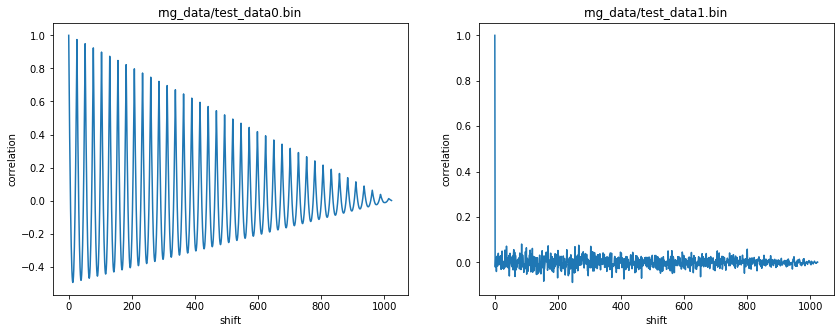

In [8]:
import matplotlib.pyplot as plt

def plot_autocorr(ax, title, data):
    ax.plot(range(len(data)), data)
    ax.set_title(title)
    ax.set_xlabel('shift')
    ax.set_ylabel('correlation')

fig1 = plt.figure(figsize=(14, 5)) 
ax1 = plt.subplot(1, 2, 1)
plot_autocorr(ax1, data_file0, autocorr_data0)
ax2 = plt.subplot(1, 2, 2)
plot_autocorr(ax2, data_file1, autocorr_data1)
plt.show()

### Compression Test

In theory, a data set containing full entropy should be incompressible.

This property can be analyzed by using common compression tools in Linux, e.g. ``bzip2``, ``gzip``, and ``xz``.

The following analysis compresses the test data files ``rng_data/test_data0.bin`` and ``rng_data/test_data1.bin`` with different tools and shows the resulting file sizes.

In [9]:
import os

def compression_test(data_file):

    # compress data
    run = subprocess.run('bzip2 -k ' + data_file, shell=True)
    run = subprocess.run('gzip -k ' + data_file, shell=True)
    run = subprocess.run('xz -k ' + data_file, shell=True)
    
    # print results
    print('{:<48}'.format(data_file),          '-->', '{:>9}'.format(os.path.getsize(data_file)), 'bytes')
    print('{:<48}'.format(data_file + '.bz2'), '-->', '{:>9}'.format(os.path.getsize(data_file + '.bz2')), 'bytes')
    print('{:<48}'.format(data_file + '.gz'),  '-->', '{:>9}'.format(os.path.getsize(data_file + '.gz')), 'bytes')
    print('{:<48}'.format(data_file + '.xz'),  '-->', '{:>9}'.format(os.path.getsize(data_file + '.xz')), 'bytes')
    print('')
    
    # delete temporary files
    run = subprocess.run('rm ' + data_file + '.bz2 ' + data_file + '.gz ' + data_file + '.xz', shell=True)
    
data_file0 = 'rng_data/test_data0.bin'
data_file1 = 'rng_data/test_data1.bin'

compression_test(data_file0)
compression_test(data_file1)

rng_data/test_data0.bin                          -->      1024 bytes
rng_data/test_data0.bin.bz2                      -->        96 bytes
rng_data/test_data0.bin.gz                       -->        70 bytes
rng_data/test_data0.bin.xz                       -->       104 bytes

rng_data/test_data1.bin                          -->      1024 bytes
rng_data/test_data1.bin.bz2                      -->      1334 bytes
rng_data/test_data1.bin.gz                       -->      1062 bytes
rng_data/test_data1.bin.xz                       -->      1084 bytes



---

## Exercise 3.1: RNG Output Data Analysis on STM32MP157C Board

Assume that you are looking for a good RNG implementation for your board. You asked several companies to provide you with their RNG implementations for evaluation.

You received four RNG implementations, named in a typical marketing manner:

* Fast, Reliable and Cool (FRaC)
* Rock Solid as Usual (RSaU)
* You Can Count on Me (YCCoM)
* Best Random Base Ever (BRBE)

The vendors promised that all tools can be used as follows:<br>
``<tool> <output-file> <number-of-rng-bytes>``

To ease compilation, you already wrote a Makefile that builds all RNG implementations.

Makefile and all source code files are contained in the directory ``rng_implementations``.

In [10]:
execute_vm_command('ls -l rng_implementations')

total 76
-rwxrwxr-x 1 student student 11028 Oct 29 11:43 best_random_base_ever
-rw-rw-r-- 1 student student  9060 Jan 17  2023 best_random_base_ever.c
-rwxrwxr-x 1 student student  8392 Oct 29 11:43 fast_reliable_and_cool
-rw-rw-r-- 1 student student  1000 Jan 17  2023 fast_reliable_and_cool.c
-rw-rw-r-- 1 student student   580 Jan 17  2023 Makefile
-rwxrwxr-x 1 student student  8424 Oct 29 11:43 rock_solid_as_usual
-rw-rw-r-- 1 student student   792 Jan 17  2023 rock_solid_as_usual.c
-rwxrwxr-x 1 student student  8392 Oct 29 11:43 you_can_count_on_me
-rw-rw-r-- 1 student student   749 Jan 17  2023 you_can_count_on_me.c



**Preparation and Data Collection Tasks:**

1. Connect to the STM32MP157C board by using ``ssh``
2. Collect 10 kilobytes (10240 bytes) of data from each RNG type

**Data Analysis Task:**

1. Use the statistical analysis tools introduced above to analyze the collected data
2. Identify the two implementations that yield the most promising results

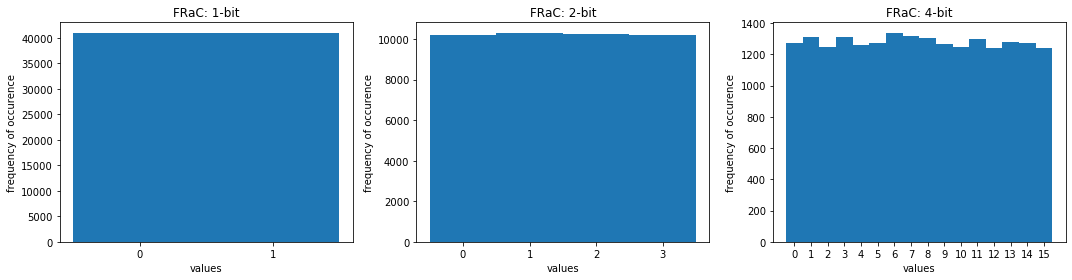

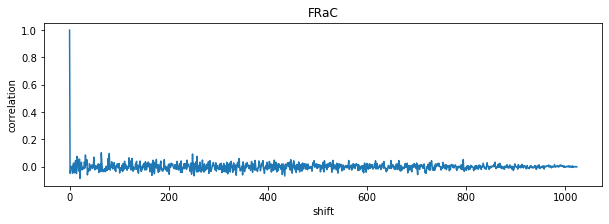

rng_data/frac.bin                                -->     10240 bytes
rng_data/frac.bin.bz2                            -->     10626 bytes
rng_data/frac.bin.gz                             -->     10272 bytes
rng_data/frac.bin.xz                             -->     10300 bytes



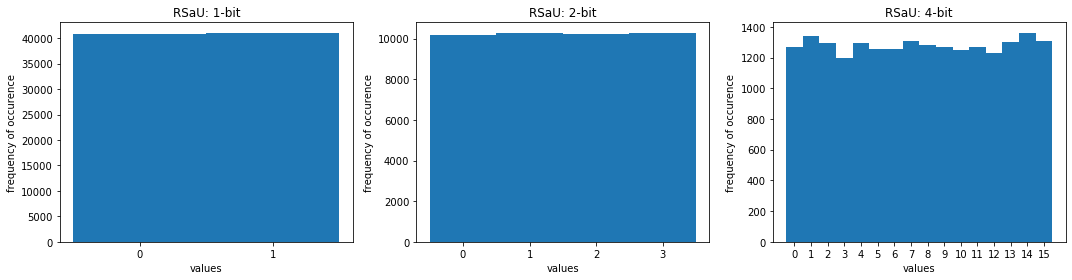

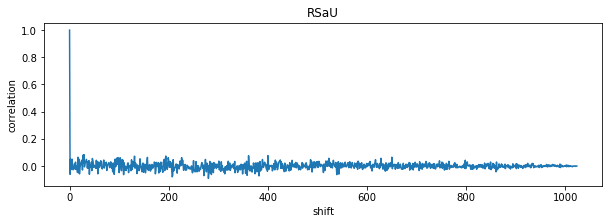

rng_data/rsau.bin                                -->     10240 bytes
rng_data/rsau.bin.bz2                            -->     10710 bytes
rng_data/rsau.bin.gz                             -->     10272 bytes
rng_data/rsau.bin.xz                             -->     10300 bytes



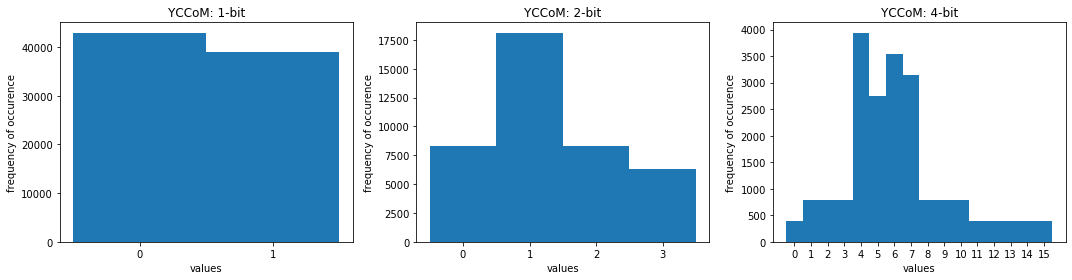

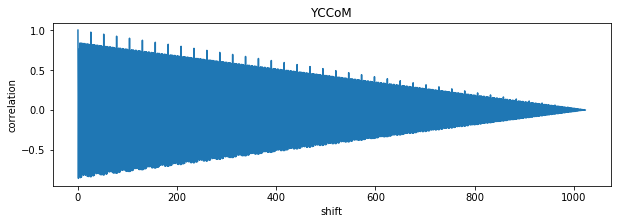

rng_data/yccom.bin                               -->     10240 bytes
rng_data/yccom.bin.bz2                           -->       117 bytes
rng_data/yccom.bin.gz                            -->       103 bytes
rng_data/yccom.bin.xz                            -->       136 bytes



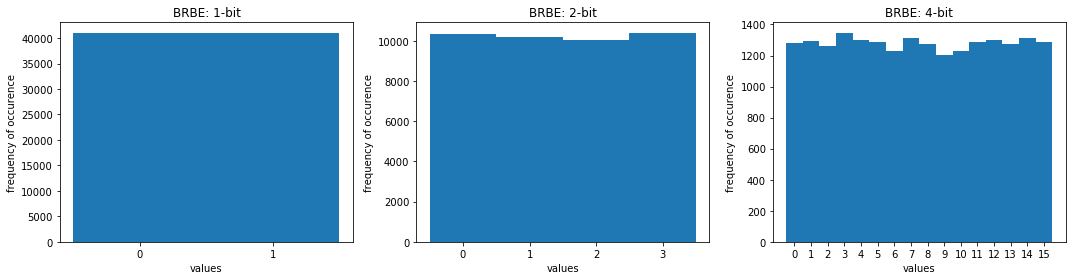

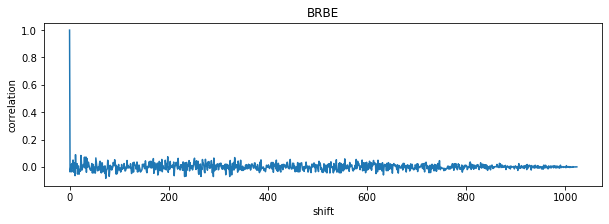

rng_data/brbe.bin                                -->     10240 bytes
rng_data/brbe.bin.bz2                            -->     10715 bytes
rng_data/brbe.bin.gz                             -->     10272 bytes
rng_data/brbe.bin.xz                             -->     10300 bytes



In [11]:
# TODO
files = {
    "FRaC": "rng_data/frac.bin",
    "RSaU": "rng_data/rsau.bin",
    "YCCoM": "rng_data/yccom.bin",
    "BRBE": "rng_data/brbe.bin",
}

for name, path in files.items():
    tuples = generate_tuples(path)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, bits, values in zip(axes, [1, 2, 4], tuples):
        plot_hist(ax, f"{name}: {bits}-bit", bits, values)
    plt.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(10, 3))
    plot_autocorr(ax, name, autocorrelate(path))
    plt.show()

    compression_test(path)

In [12]:
# TODO

In [13]:
# TODO

In [14]:
# TODO

---

## Exercise 3.2: Further Analysis of the Two Most Promising RNGs

Take the two most promising RNGs from the first exercise and perform further analyses.

There are at least two ways to continue:

1. **Source code analysis** to identify strengths and weaknesses


2. Collect several random data files from each RNG, e.g. 10x 10240 bytes, and analyze the results for **reset problems**, i.e. recurring patterns and numbers after calling the tool again and again.


**Hint:**<br>
Concatenating several files in Linux can be achieved by this command: ``cat file1 file2 file3 > concatenated_file``

In [15]:
# TODO

In [16]:
# TODO